In [ ]:
!pip install transformers wordcloud gensim scikit-learn imbalanced-learn matplotlib seaborn tensorflow

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.metrics import confusion_matrix, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from wordcloud import WordCloud
from transformers import RobertaTokenizer, RobertaForSequenceClassification, RobertaModel # Removed AdamW from this line
from transformers import pipeline # Added this line to import AdamW from the correct submodule
from gensim.models import Word2Vec
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Conv1D, GlobalMaxPooling1D, Dense, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical

from imblearn.over_sampling import SMOTE

In [ ]:
df = pd.read_csv("fix_data.csv")  # atau gunakan files.upload() di Colab

In [ ]:
roberta_classifier = pipeline('sentiment-analysis', model="cardiffnlp/twitter-xlm-roberta-base-sentiment-multilingual",tokenizer="cardiffnlp/twitter-xlm-roberta-base-sentiment-multilingual")
df['label'] = df['full_text'].apply(lambda x: roberta_classifier(x[:512])[0]['label'])

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/982 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/443 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

Device set to use cpu


In [ ]:
# Stopwords manual Bahasa Indonesia
stopwords_id = set([
    'yang', 'dan', 'di', 'ke', 'dari', 'ini', 'untuk', 'dengan', 'pada',
    'ada', 'sudah', 'saja', 'juga', 'mereka', 'kami', 'kita', 'saya',
    'aku', 'apa', 'mengapa', 'bagaimana', 'dalam', 'itu', 'oleh',
    'sebagai', 'akan', 'jadi', 'lagi', 'hanya', 'lebih',
    'kalau', 'ya', 'oh', 'nah', 'kok', 'lah', 'yg', 'gw', 'gua',
    'gue', 'orang', 'lu', 'kau'
])

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+|https\S+", '', text)
    text = re.sub(r'@\w+|#', '', text)
    text = re.sub(r"[^\w\s]", '', text)
    text = re.sub(r"\d+", '', text)
    text = re.sub(r"\s+", ' ', text).strip()
    text = ' '.join([word for word in text.split() if word not in stopwords_id])
    return text

df['cleaned_text'] = df['full_text'].apply(clean_text)
df[['full_text', 'cleaned_text']].head()


,full_text,cleaned_text
0,btul dia alasan oc ku cwek Sunda lahir ️,btul dia alasan oc ku cwek sunda lahir
1,@EternalFirstLov Isu Indonesia Gelap Hanya Pro...,isu indonesia gelap provokasi jangan terpancin...
2,@EternalFirstLov Melawan Disinformasi: Indones...,melawan disinformasi indonesia tidak gelap tap...
3,@yusuf_my1 @hamas191 @prabowo @Kemhan_RI @List...,gelap banget pendidikan rusak pekerjaan banyak...
4,@abu_waras Indonesia gelap pala lu peang https...,indonesia gelap pala peang


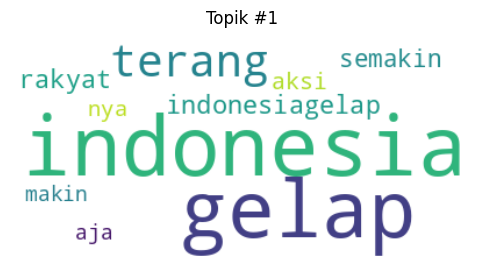

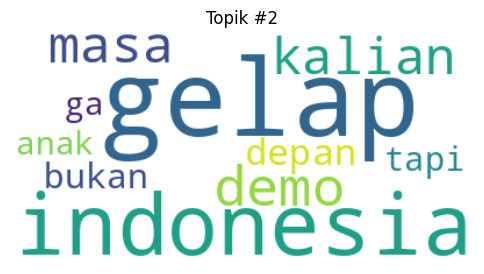

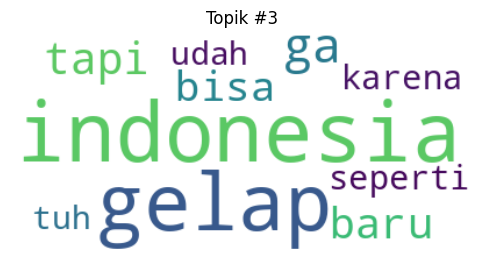

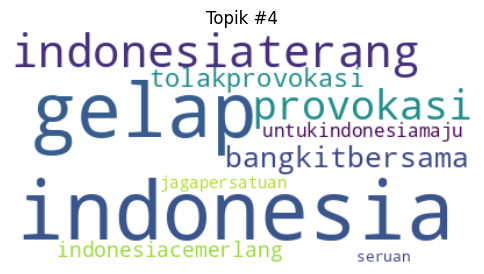

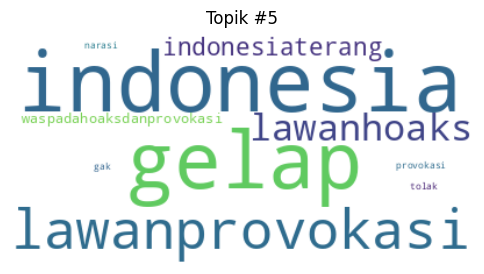

In [ ]:
vectorizer = CountVectorizer(max_df=0.95, min_df=2, stop_words='english')
doc_term_matrix = vectorizer.fit_transform(df['cleaned_text'])

lda_model = LatentDirichletAllocation(n_components=5, random_state=42)
lda_model.fit(doc_term_matrix)

def plot_top_words(model, feature_names, n_top_words=10):
    for topic_idx, topic in enumerate(model.components_):
        plt.figure(figsize=(6, 4))
        words = {feature_names[i]: topic[i] for i in topic.argsort()[:-n_top_words - 1:-1]}
        wordcloud = WordCloud(background_color='white').generate_from_frequencies(words)
        plt.imshow(wordcloud, interpolation='bilinear')
        plt.axis('off')
        plt.title(f"Topik #{topic_idx + 1}")
        plt.show()

feature_names = vectorizer.get_feature_names_out()
plot_top_words(lda_model, feature_names)


In [ ]:
print(df['label'].value_counts())


label
negative    869
positive    295
neutral     104
Name: count, dtype: int64


In [ ]:
#1. WORD2VEC TRAINING
sentences = [text.split() for text in df['cleaned_text']]
w2v = Word2Vec(
        sentences     = sentences,
        vector_size   = 100,
        window        = 5,
        min_count     = 1,
        workers       = 4,
        epochs        = 30
)

def vectorize(text, dim=100):
    vecs = [w2v.wv[w] for w in text.split() if w in w2v.wv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(dim)

X_vec = np.vstack([vectorize(t) for t in df['cleaned_text']])
y     = df['label'].values          # pastikan sudah 0‑1‑2

#2. STANDARD SCALER
scaler   = StandardScaler()
X_scaled = scaler.fit_transform(X_vec)

#3. SMOTE BALANCING
print("Distribusi label sebelum SMOTE :", Counter(y))
smote  = SMOTE(random_state=42)
X_bal, y_bal = smote.fit_resample(X_scaled, y)
print("Distribusi label setelah  SMOTE :", Counter(y_bal))

Distribusi label sebelum SMOTE : Counter({'negative': 869, 'positive': 295, 'neutral': 104})
Distribusi label setelah  SMOTE : Counter({'positive': 869, 'negative': 869, 'neutral': 869})


🔨  Training NEW pure‑CNN model ...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/20
66/66 - 19s - 283ms/step - accuracy: 0.3348 - loss: 1.8804 - val_accuracy: 0.3333 - val_loss: 1.3926 - learning_rate: 1.0000e-04
Epoch 2/20
66/66 - 11s - 174ms/step - accuracy: 0.3338 - loss: 1.6334 - val_accuracy: 0.3333 - val_loss: 1.3771 - learning_rate: 1.0000e-04
Epoch 3/20
66/66 - 24s - 360ms/step - accuracy: 0.3362 - loss: 1.5517 - val_accuracy: 0.3333 - val_loss: 1.3117 - learning_rate: 1.0000e-04
Epoch 4/20
66/66 - 13s - 196ms/step - accuracy: 0.3856 - loss: 1.4306 - val_accuracy: 0.4234 - val_loss: 1.2234 - learning_rate: 1.0000e-04
Epoch 5/20
66/66 - 10s - 151ms/step - accuracy: 0.4791 - loss: 1.2521 - val_accuracy: 0.5479 - val_loss: 1.1041 - learning_rate: 1.0000e-04
Epoch 6/20
66/66 - 10s - 154ms/step - accuracy: 0.5990 - loss: 0.9511 - val_accuracy: 0.6284 - val_loss: 0.9600 - learning_rate: 1.0000e-04
Epoch 7/20
66/66 - 9s - 143ms/step - accuracy: 0.6360 - loss: 0.7125 - val_accuracy: 0.6418 - val_loss: 0.8283 - learning_rate: 1.0000e-04
Epoch 8/20
66/66 - 10

✅  Model saved to sentiment_cnn.h5
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step

Classification Report
               precision    recall  f1-score   support

    negative       0.97      0.59      0.73       174
     neutral       0.89      1.00      0.94       174
    positive       0.76      0.97      0.86       174

    accuracy                           0.85       522
   macro avg       0.87      0.85      0.84       522
weighted avg       0.87      0.85      0.84       522



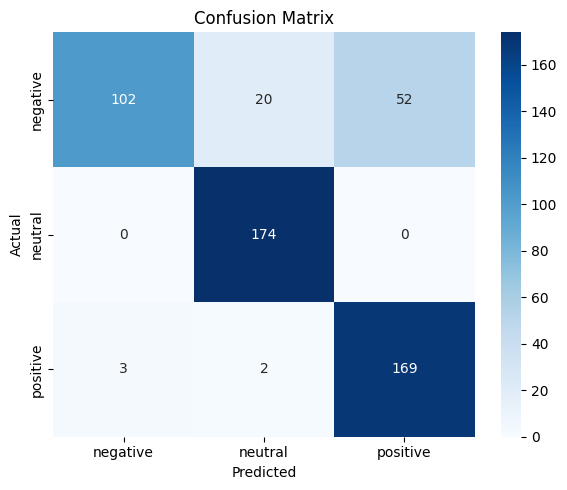

In [ ]:
import os, gzip, pickle
MODEL_PATH     = "sentiment_cnn.h5"
TOKENIZER_PATH = "tokenizer.pkl.gz"

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.utils import class_weight, resample
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import (Embedding, Conv1D, GlobalMaxPooling1D,
                                     Dense, Dropout)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

#2  Hyper‑parameters
MAX_WORDS, MAX_LEN = 8000, 120
EMB_DIM, LSTM_UNITS = 128, 64
BATCH_SIZE, EPOCHS, SEED = 32, 20, 42
idx2label = ['negative','neutral','positive']

#3  Data prep (sama)
label_mapping = {'negative':0,'neutral':1,'positive':2}
df['label_num'] = df['label'].map(label_mapping)

maj, neu, pos = (df[df.label_num==i] for i in range(3))
tgt = len(maj)
neu_up = resample(neu, replace=True, n_samples=tgt, random_state=SEED)
pos_up = resample(pos, replace=True, n_samples=tgt, random_state=SEED)
df_balanced = pd.concat([maj, neu_up, pos_up])

# tokenizer: buat atau load
if os.path.exists(TOKENIZER_PATH):
    with gzip.open(TOKENIZER_PATH,'rb') as f: tokenizer = pickle.load(f)
else:
    tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token='<OOV>')
    tokenizer.fit_on_texts(df_balanced['cleaned_text'])
    with gzip.open(TOKENIZER_PATH,'wb') as f: pickle.dump(tokenizer,f)

seqs = tokenizer.texts_to_sequences(df_balanced['cleaned_text'])
X_all = pad_sequences(seqs, maxlen=MAX_LEN)
y_all = to_categorical(df_balanced['label_num'], 3)

X_train,X_test,y_train,y_test = train_test_split(
    X_all,y_all,test_size=0.2,random_state=SEED,stratify=y_all)

cw = class_weight.compute_class_weight('balanced',
        classes=np.unique(df['label_num']), y=df['label_num'])
cw = dict(enumerate(cw))

#4  Build OR Load model
if os.path.exists(MODEL_PATH):
    print("🔄  Loading existing model ...")
    model = load_model(MODEL_PATH)

else:
    print("🔨  Training NEW pure‑CNN model ...")
    model = Sequential([
        Embedding(MAX_WORDS, EMB_DIM, input_length=MAX_LEN),

        Conv1D(128, 5, activation='relu', padding='same'),
        Conv1D(128, 5, activation='relu', padding='same'),
        GlobalMaxPooling1D(),

        Dense(64, activation='relu'),
        Dropout(0.5),
        Dense(3, activation='softmax')
    ])

    model.compile(
        loss='categorical_crossentropy',
        optimizer=Adam(1e-4),
        metrics=['accuracy']
    )

    cb = [
        EarlyStopping(monitor='val_loss', patience=4,
                      restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                          patience=2, min_lr=1e-6, verbose=1)
    ]

    model.fit(
        X_train, y_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_data=(X_test, y_test),
        class_weight=cw,
        callbacks=cb,
        verbose=2
    )

    model.save(MODEL_PATH)
    print(f"✅  Model saved to {MODEL_PATH}")


#5  Evaluate
y_pred = model.predict(X_test); y_pred_cls=np.argmax(y_pred,1); y_true=np.argmax(y_test,1)
print("\nClassification Report\n",
      classification_report(y_true,y_pred_cls,target_names=idx2label))

cm = confusion_matrix(y_true,y_pred_cls)
plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',
            xticklabels=idx2label,yticklabels=idx2label)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion Matrix')
plt.tight_layout(); plt.show()

In [ ]:
# IMPORT & LOAD
import numpy as np, gzip, pickle
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import load_model
from sklearn.metrics import classification_report, accuracy_score

MODEL_PATH     = "sentiment_cnn.h5"
TOKENIZER_PATH = "tokenizer.pkl.gz"       # ganti jika .pkl
MAX_LEN        = 120                      # sama dgn saat training
idx2label      = ['negative','neutral','positive']

# load model
model = load_model(MODEL_PATH)
print("✅ model loaded")

# load tokenizer
with gzip.open(TOKENIZER_PATH, "rb") as f:
    tokenizer = pickle.load(f)
print("✅ tokenizer loaded")

#1  FUNGSI PREDIKSI
def predict_and_evaluate(texts, true_labels=None):
    seq   = tokenizer.texts_to_sequences(texts)
    pads  = pad_sequences(seq, maxlen=MAX_LEN, padding='post')
    probs = model.predict(pads)
    pred_idx = np.argmax(probs, axis=1)
    preds = [idx2label[i] for i in pred_idx]

    # tampilkan detail per‑teks
    for t, p_lab, pr in zip(texts, preds, probs):
        print(f"Text : {t}")
        print(f"Predicted : {p_lab}")
        for lab, prob in zip(idx2label, pr):
            print(f"  {lab:<8}: {prob:.4f}")
        print("-"*40)

    # evaluasi jika label sebenarnya tersedia
    if true_labels is not None:
        # pastikan format label cocok dengan idx2label
        y_true = [idx2label.index(lab) for lab in true_labels]
        acc    = accuracy_score(y_true, pred_idx)
        print(f"\nOverall accuracy: {acc:.3f}")
        print(classification_report(y_true, pred_idx, target_names=idx2label))

#2  CONTOH PEMAKAIAN
new_texts  = [
    "Tolak provokasi Indonesia Gelap.",
    "Gelap banget indonesia, Pendidikan rusak, banyak phk dimana mana.",
    "Percayain aja sama pemerintah gais."
]
# opsi: label ground‑truth, harus negative/neutral/positive jika mau evaluasi
true_labels = None   # ['negative','negative','neutral']

predict_and_evaluate(new_texts, true_labels)


✅ model loaded
✅ tokenizer loaded
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
Text : Tolak provokasi Indonesia Gelap.
Predicted : neutral
  negative: 0.0084
  neutral : 0.9902
  positive: 0.0014
----------------------------------------
Text : Gelap banget indonesia, Pendidikan rusak, banyak phk dimana mana.
Predicted : negative
  negative: 0.6700
  neutral : 0.0313
  positive: 0.2988
----------------------------------------
Text : Percayain aja sama pemerintah gais.
Predicted : neutral
  negative: 0.0082
  neutral : 0.9905
  positive: 0.0013
----------------------------------------


In [ ]:
# 1. Pastikan fungsi prediksi mengembalikan hasil
def predict_and_evaluate(texts, true_labels=None):
    seq   = tokenizer.texts_to_sequences(texts)
    pads  = pad_sequences(seq, maxlen=MAX_LEN, padding='post')
    probs = model.predict(pads)
    pred_idx = np.argmax(probs, axis=1)
    preds = [idx2label[i] for i in pred_idx]
    return preds


# 2. Prediksi dan tambahkan ke dataframe
df['predicted_label'] = predict_and_evaluate(df['cleaned_text'].tolist())


# 3. Fungsi ambil teks berdasarkan label
def get_text_by_label(df, label_name):
    return " ".join(df[df['predicted_label'] == label_name]['cleaned_text'].dropna().astype(str))


# 4. Fungsi untuk membuat WordCloud
from wordcloud import WordCloud
import matplotlib.pyplot as plt

def create_wordcloud(text, title):
    wordcloud = WordCloud(
        width=1000,
        height=500,
        max_font_size=100,
        background_color='black',
        colormap='viridis',
        collocations=False
    ).generate(text)

    plt.figure(figsize=(12, 6))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis("off")
    plt.title(title, fontsize=18, fontweight='bold', color='white', pad=20)
    plt.tight_layout(pad=0)
    plt.show()


40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step


## WordCloud Sentimen Negatif

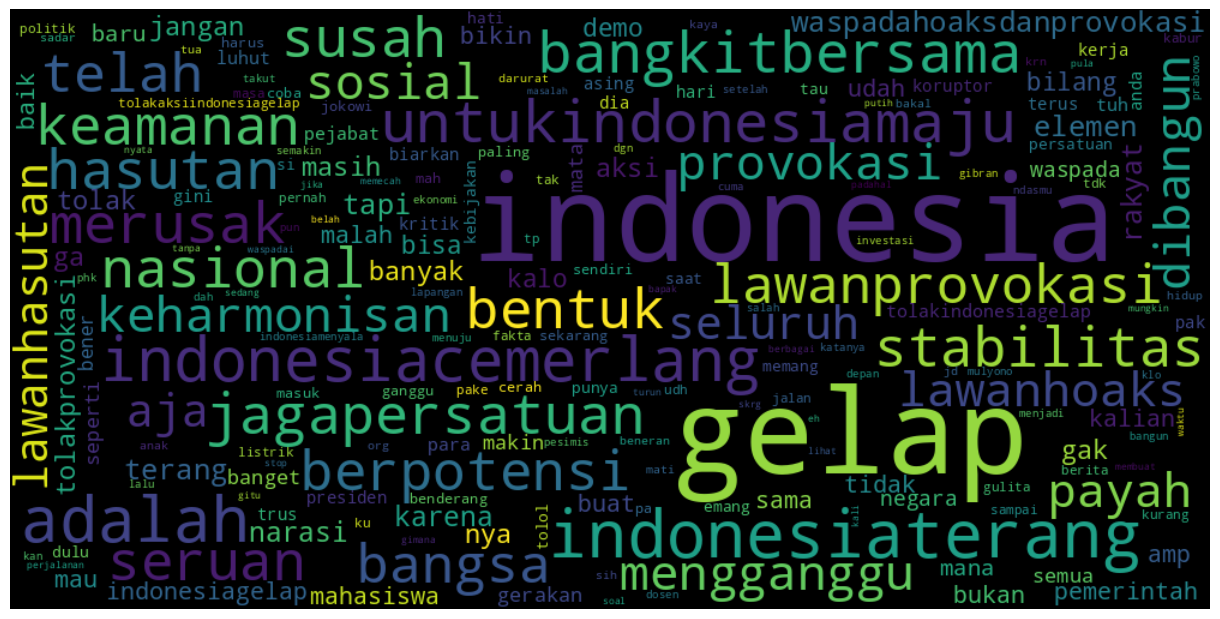

In [ ]:
from IPython.display import display, Markdown

sentimen_negatif = get_text_by_label(df, 'negative')
display(Markdown("## WordCloud Sentimen Negatif"))
create_wordcloud(sentimen_negatif, '')


## WordCloud Sentimen Netral

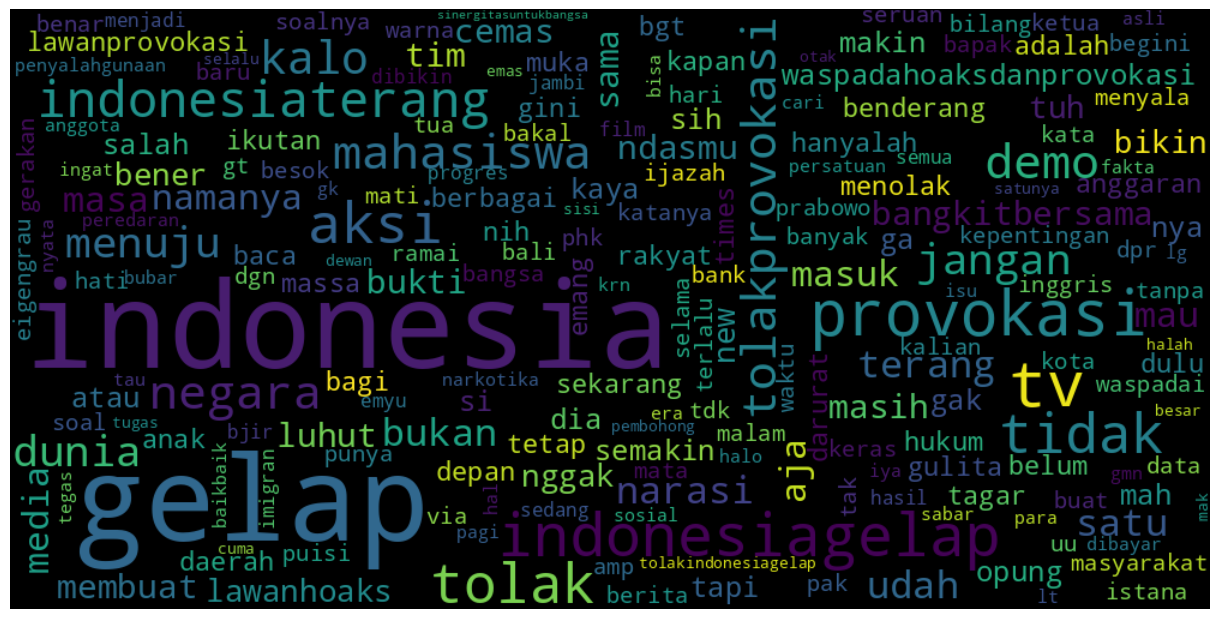

In [ ]:
sentimen_netral = get_text_by_label(df, 'neutral')
display(Markdown("## WordCloud Sentimen Netral"))
create_wordcloud(sentimen_netral, '')

## WordCloud Sentimen Positif

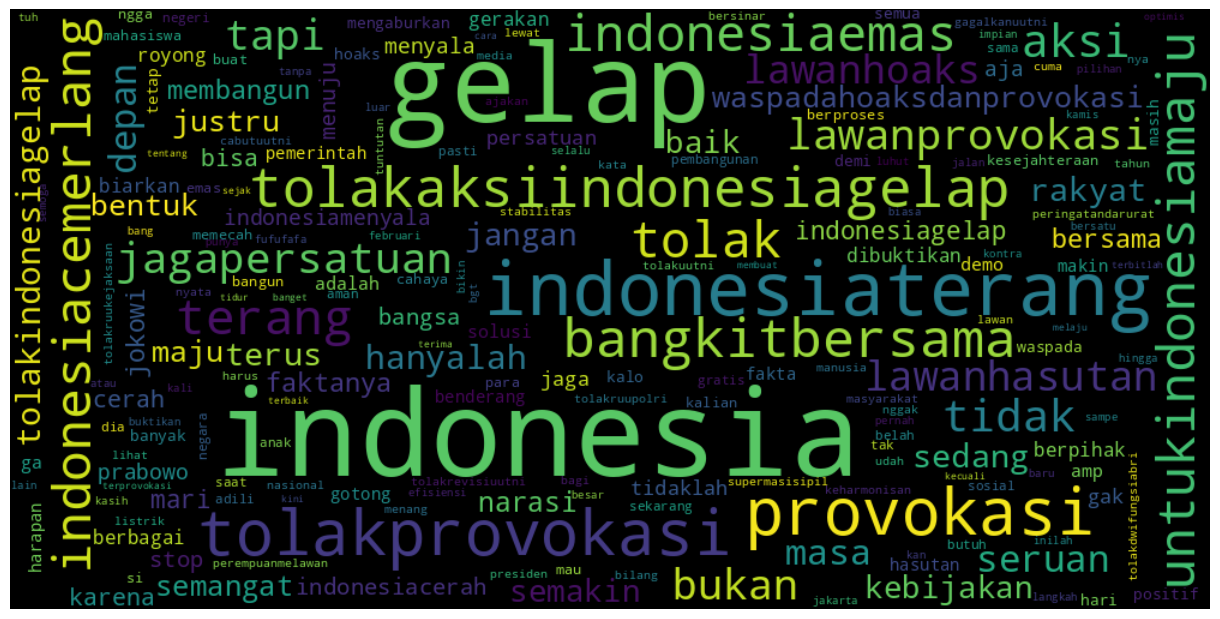

In [ ]:
sentimen_positif = get_text_by_label(df, 'positive')
display(Markdown("## WordCloud Sentimen Positif"))
create_wordcloud(sentimen_positif, '')

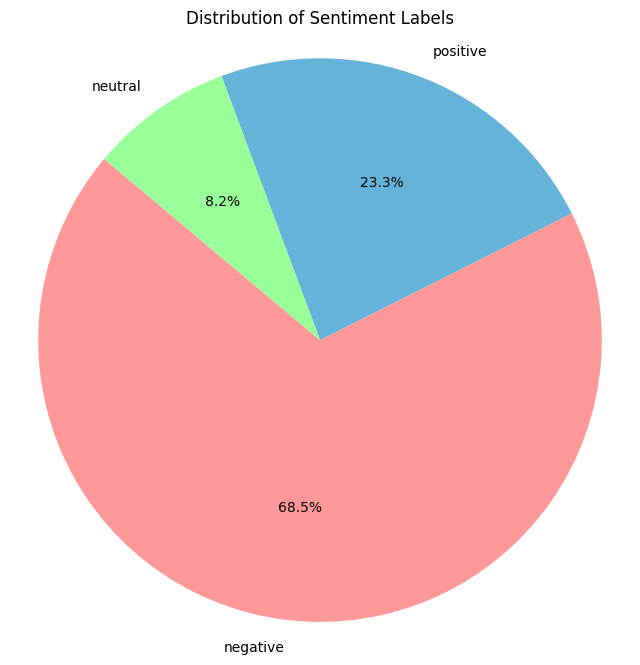

In [ ]:
sentiment_counts = df['label'].value_counts()

# Get the labels and sizes for the pie chart
labels = sentiment_counts.index
sizes = sentiment_counts.values

# Create the pie chart
plt.figure(figsize=(8, 8))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=140, colors=['#ff9999','#66b3da','#99ff99'])
plt.title('Distribution of Sentiment Labels')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()